In [2]:
import pandas as pd

df = pd.read_csv('student_habits_performance.csv')
df.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   str    
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   str    
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   str    
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   str    
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    str    
 12  internet_quality               1000 non-null   str    
 13  

In [4]:
df.shape

(1000, 16)

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="darkgrid")

In [6]:
df.isna().sum().sum()

np.int64(91)

In [7]:
df = df.dropna()

In [8]:
df.isna().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
import warnings
warnings.filterwarnings("ignore")

df.describe()

,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
count,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000
mean,20.475248,3.538724,2.504620,1.830363,83.880308,6.474037,3.051705,5.466447,69.558196
std,2.302721,1.469730,1.164802,1.071251,9.453622,1.218943,2.035632,2.857525,16.929436
min,17.000000,0.000000,0.000000,0.000000,56.000000,3.200000,0.000000,1.000000,18.400000
25%,18.000000,2.500000,1.700000,1.000000,77.500000,5.600000,1.000000,3.000000,58.400000
50%,20.000000,3.500000,2.500000,1.800000,84.200000,6.500000,3.000000,5.000000,70.400000
75%,22.000000,4.500000,3.300000,2.600000,90.700000,7.300000,5.000000,8.000000,81.300000
max,24.000000,8.300000,7.200000,5.400000,100.000000,10.000000,6.000000,10.000000,100.000000


In [11]:
df.describe(include=['object'])

,student_id,gender,part_time_job,diet_quality,parental_education_level,internet_quality,extracurricular_participation
count,909,909,909,909,909,909,909
unique,909,3,2,3,3,3,2
top,S1000,Male,No,Fair,High School,Good,No
freq,1,440,713,396,392,410,620


In [12]:
categorical_cols = ['gender', 'part_time_job', 'diet_quality','parental_education_level', 'internet_quality', 'extracurricular_participation']

In [13]:
for col in categorical_cols:
    print(f"Value count for {col}: \n {df[col].value_counts()}")

Value count for gender: 
 gender
Male      440
Female    433
Other      36
Name: count, dtype: int64
Value count for part_time_job: 
 part_time_job
No     713
Yes    196
Name: count, dtype: int64
Value count for diet_quality: 
 diet_quality
Fair    396
Good    347
Poor    166
Name: count, dtype: int64
Value count for parental_education_level: 
 parental_education_level
High School    392
Bachelor       350
Master         167
Name: count, dtype: int64
Value count for internet_quality: 
 internet_quality
Good       410
Average    352
Poor       147
Name: count, dtype: int64
Value count for extracurricular_participation: 
 extracurricular_participation
No     620
Yes    289
Name: count, dtype: int64


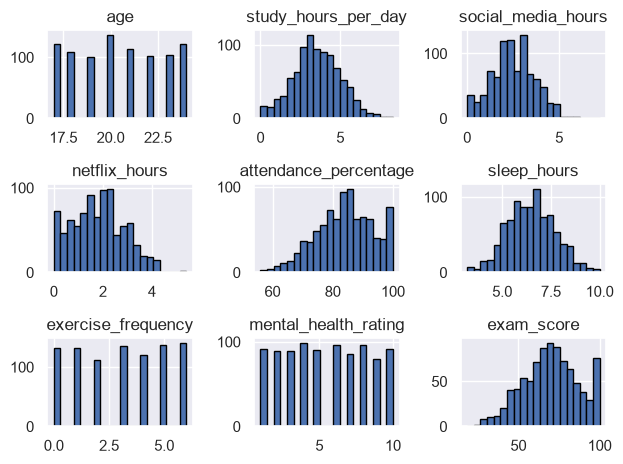

In [14]:
df.hist(bins=20, edgecolor='black',)
plt.tight_layout()
plt.show()

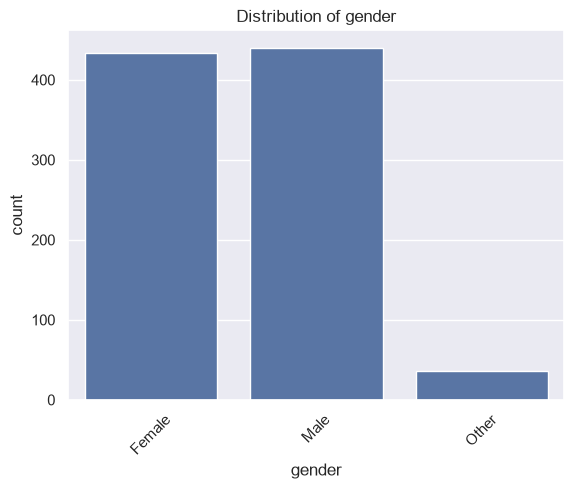

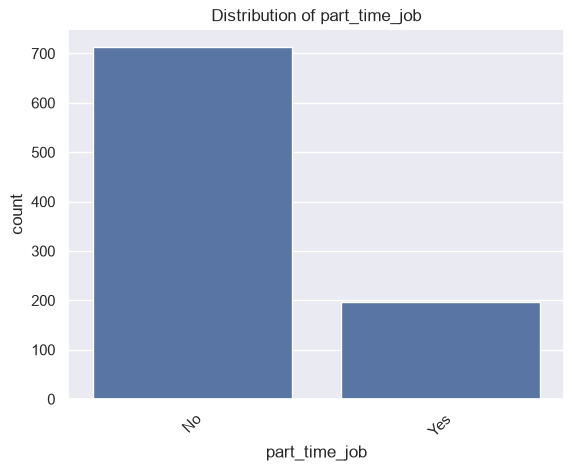

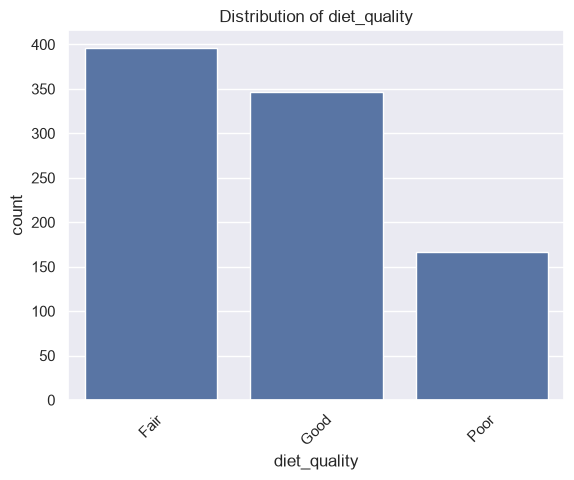

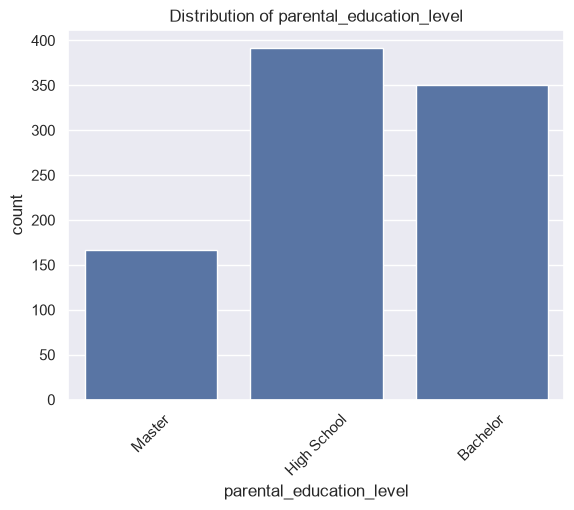

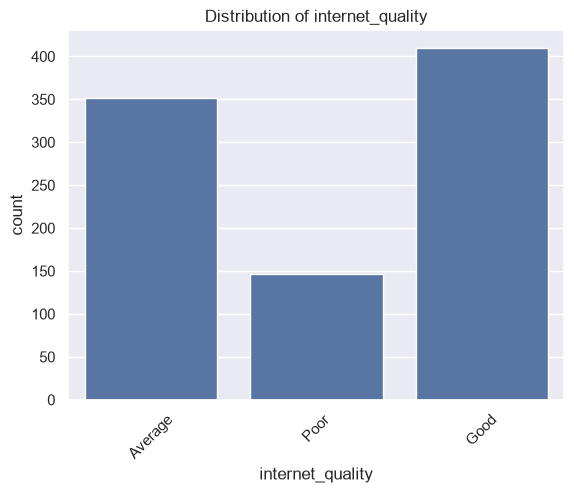

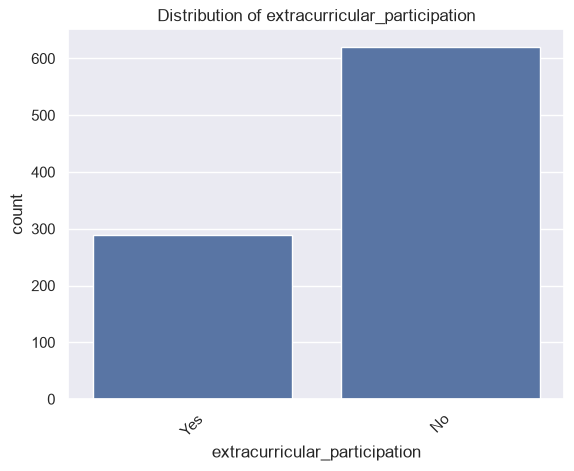

In [15]:
for col in categorical_cols:
    sns.countplot(data=df, x=col)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

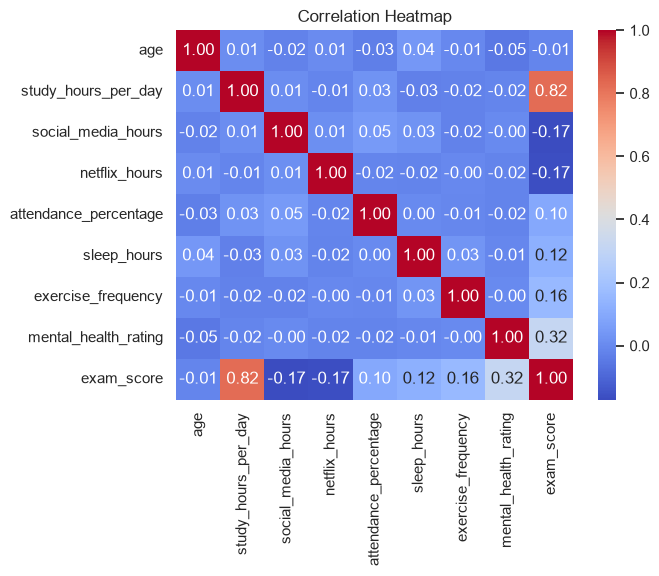

In [16]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [17]:
df.describe().columns

Index(['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
       'attendance_percentage', 'sleep_hours', 'exercise_frequency',
       'mental_health_rating', 'exam_score'],
      dtype='str')

In [18]:
num_features = ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
       'attendance_percentage', 'sleep_hours', 'exercise_frequency',
       'mental_health_rating']

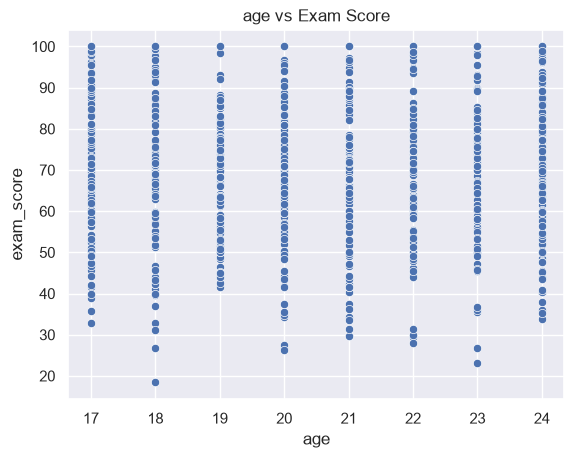

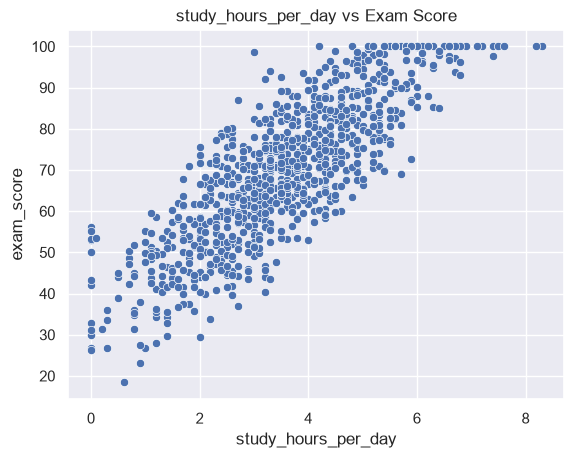

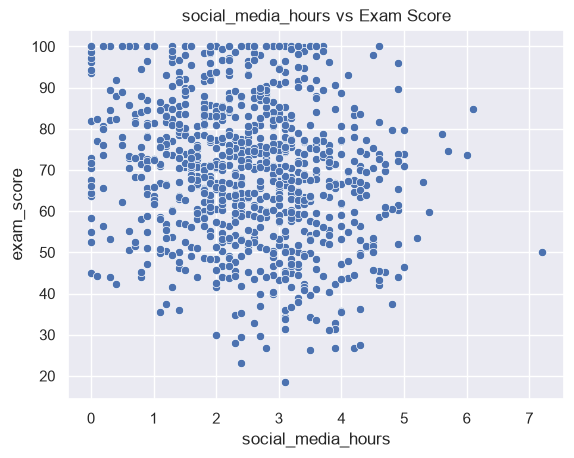

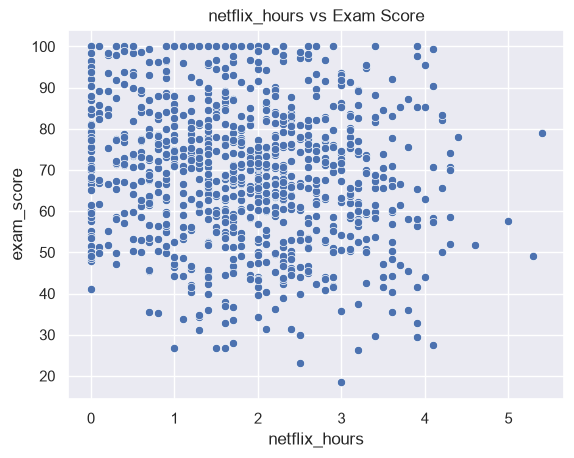

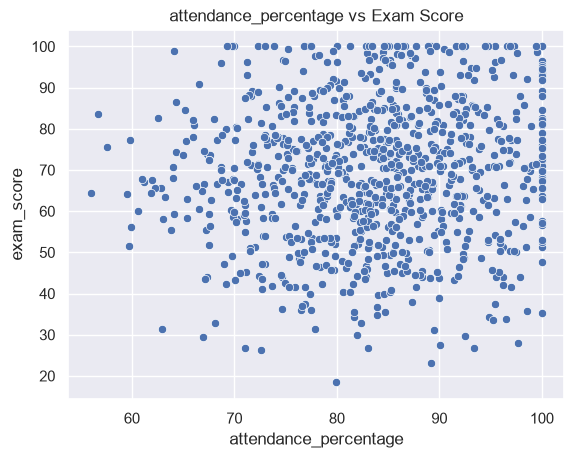

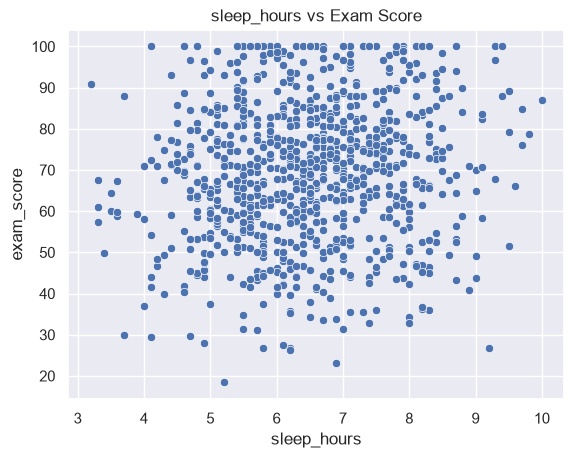

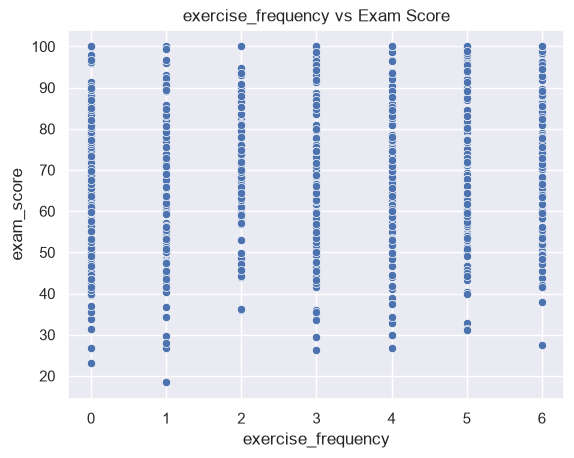

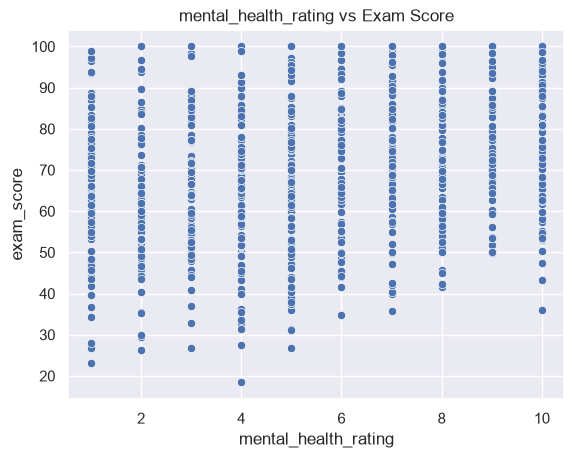

In [19]:
for feture in num_features :
    sns.scatterplot(data=df, x=feture, y='exam_score')
    plt.title(f"{feture} vs Exam Score")
    plt.show()

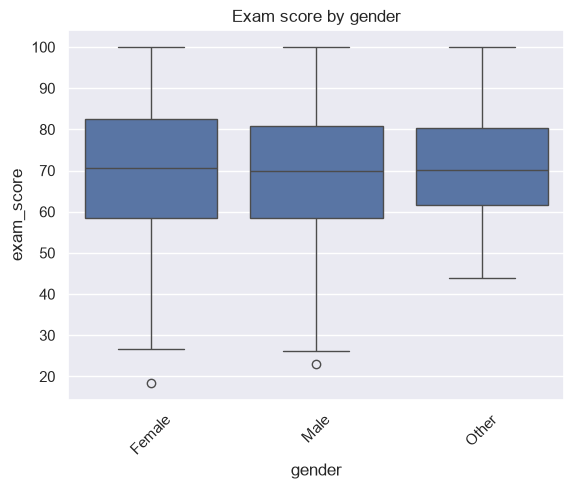

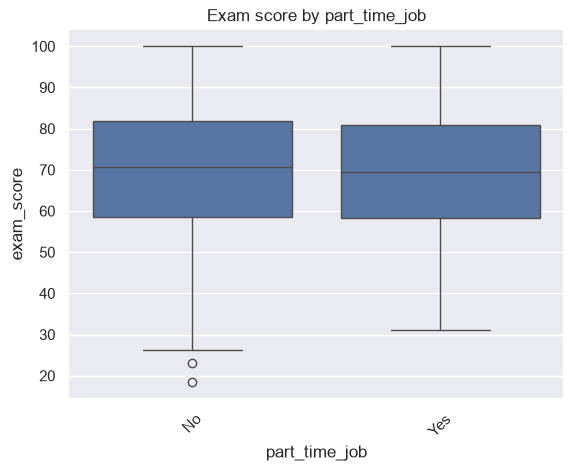

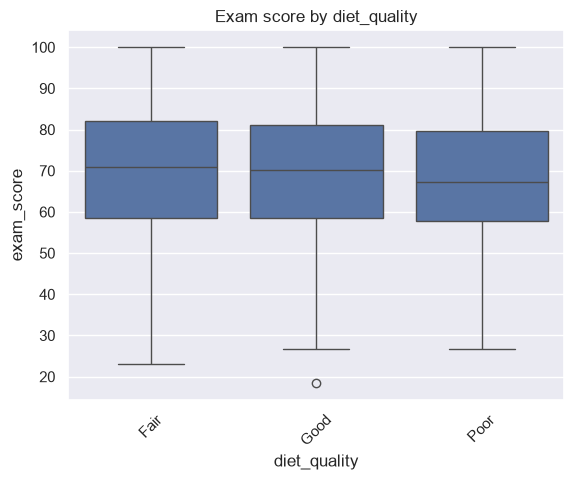

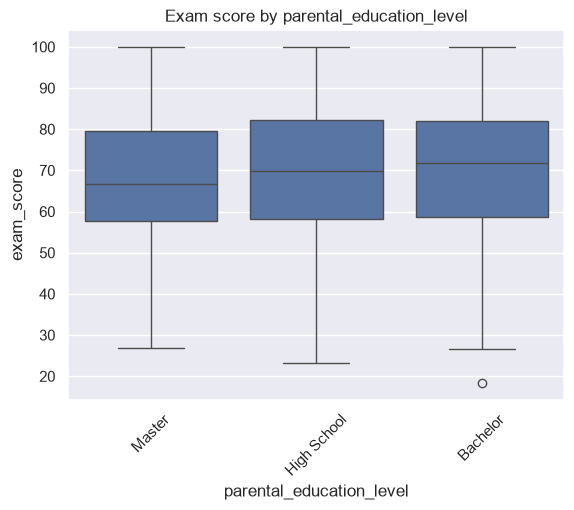

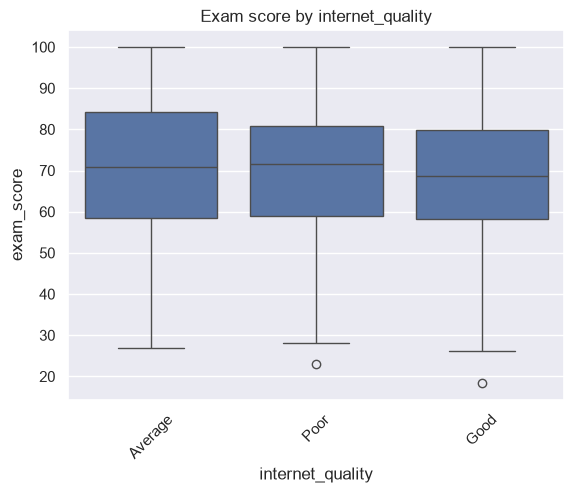

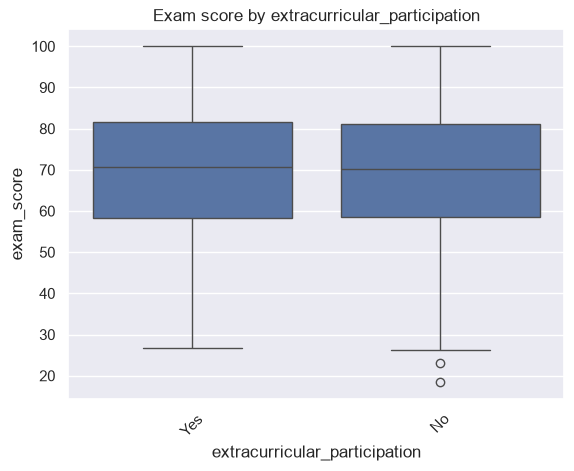

In [20]:
for col in categorical_cols:
    sns.boxplot(data=df, x=col, y="exam_score")
    plt.title(f"Exam score by {col}")
    plt.xticks(rotation=45)
    plt.show()

In [21]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

In [22]:
df.columns

Index(['student_id', 'age', 'gender', 'study_hours_per_day',
       'social_media_hours', 'netflix_hours', 'part_time_job',
       'attendance_percentage', 'sleep_hours', 'diet_quality',
       'exercise_frequency', 'parental_education_level', 'internet_quality',
       'mental_health_rating', 'extracurricular_participation', 'exam_score'],
      dtype='str')

In [23]:
df.head(2)

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0


In [24]:
features = ["study_hours_per_day","attendance_percentage","mental_health_rating", "sleep_hours","part_time_job"]
target = "exam_score"

In [25]:
df_model = df[features + [target]].copy()
df_model

,study_hours_per_day,attendance_percentage,mental_health_rating,sleep_hours,part_time_job,exam_score
0,0.0,85.0,8,8.0,No,56.2
1,6.9,97.3,8,4.6,No,100.0
2,1.4,94.8,1,8.0,No,34.3
3,1.0,71.0,1,9.2,No,26.8
4,5.0,90.9,1,4.9,No,66.4
...,...,...,...,...,...,...
995,2.6,77.0,6,7.5,No,76.1
996,2.9,86.0,6,6.8,Yes,65.9
997,3.0,61.9,9,6.5,No,64.4
998,5.4,100.0,1,7.6,Yes,69.7


In [26]:
le = LabelEncoder()
df_model["part_time_job"] = le.fit_transform(df_model['part_time_job'])
df_model

,study_hours_per_day,attendance_percentage,mental_health_rating,sleep_hours,part_time_job,exam_score
0,0.0,85.0,8,8.0,0,56.2
1,6.9,97.3,8,4.6,0,100.0
2,1.4,94.8,1,8.0,0,34.3
3,1.0,71.0,1,9.2,0,26.8
4,5.0,90.9,1,4.9,0,66.4
...,...,...,...,...,...,...
995,2.6,77.0,6,7.5,0,76.1
996,2.9,86.0,6,6.8,1,65.9
997,3.0,61.9,9,6.5,0,64.4
998,5.4,100.0,1,7.6,1,69.7


In [27]:
x = df_model[features]
y = df_model[target]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2)
len(y_train), len(y_test)

(727, 182)

In [28]:
models = {
    "LinearRegression": {
        "model": LinearRegression(),
        "params": {}
    },
    "DecisionTree": {
        "model": DecisionTreeRegressor(),
        "params": {"max_depth": [3,5,10], "min_samples_split": [2,5]}
    },
    "RandomForest": {
        "model": RandomForestRegressor(),
        "params": {"n_estimators": [50,100], "max_depth": [5,10]}
    }
}

In [29]:
best_models = []
for name, config in models.items():
    print(f"Training {name}...")

    grid = GridSearchCV(config['model'], config['params'], cv=5, scoring='neg_mean_squared_error')
    grid.fit(x_train, y_train)

    y_pred = grid.predict(x_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    best_models.append({
        "model" : name,
        "best_params": grid.best_params_,
        "rmse": rmse,
        "r2_score": r2
    })



Training LinearRegression...
Training DecisionTree...
Training RandomForest...


In [30]:
best_models

[{'model': 'LinearRegression',
  'best_params': {},
  'rmse': np.float64(7.109043447317827),
  'r2_score': 0.8189734026016405},
 {'model': 'DecisionTree',
  'best_params': {'max_depth': 5, 'min_samples_split': 2},
  'rmse': np.float64(8.882608044344524),
  'r2_score': 0.717381199333686},
 {'model': 'RandomForest',
  'best_params': {'max_depth': 5, 'n_estimators': 100},
  'rmse': np.float64(7.742992597502402),
  'r2_score': 0.7852477416184713}]

In [31]:
results_df = pd.DataFrame(best_models)
results_df.sort_values(by="rmse")

,model,best_params,rmse,r2_score
0,LinearRegression,{},7.109043,0.818973
2,RandomForest,"{'max_depth': 5, 'n_estimators': 100}",7.742993,0.785248
1,DecisionTree,"{'max_depth': 5, 'min_samples_split': 2}",8.882608,0.717381


In [32]:
import joblib

best_row = results_df.sort_values(by="rmse").iloc[0]
best_row

model          LinearRegression
best_params                  {}
rmse                   7.109043
r2_score               0.818973
Name: 0, dtype: object

In [33]:
best_model_name = best_row['model']
best_model_name

'LinearRegression'

In [34]:
best_model_config = models[best_model_name]
best_model_config

{'model': LinearRegression(), 'params': {}}

In [35]:
final_model = best_model_config['model']
final_model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[9.56,0.14,1.98,2.05,0.09]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['study_hours_per_day','attendance_percentage','mental_health_rating', 'sleep_hours','part_time_job']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.01073
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [36]:
joblib.dump(final_model, 'student_performance_model.pkl')

['student_performance_model.pkl']

In [37]:
joblib.load('student_performance_model.pkl').predict(x_test)

array([ 40.0082463 ,  49.90983882,  46.52666247, 100.68914231,
        88.10129326, 101.01138266,  73.37721953,  85.15391158,
        64.38337437,  94.28634195,  77.67278715,  95.52324961,
        74.26344109,  74.5771561 ,  48.67665262,  94.91445972,
        80.39472169,  77.26666279,  66.25211042,  62.66539553,
        65.38478204,  58.11862611,  82.34672584, 107.4516993 ,
        58.73539837,  68.10932257,  71.16711953,  76.89350005,
        63.08783432,  66.0866954 ,  49.2095591 ,  83.76282292,
        77.0077602 ,  66.70036983,  57.99851846,  81.73266078,
        73.53456232,  84.17072978,  51.1813487 ,  72.45303949,
        72.88151862,  80.25838196,  74.59798177,  91.82549796,
        79.79071474,  66.22583241,  47.74082004,  54.55013746,
        34.07217639,  50.87089394,  71.57182983,  48.56143345,
        72.24230521,  43.87777281,  68.67625259,  74.5910171 ,
        36.59323364,  63.44842876,  37.70865932,  69.09467311,
       105.01596237,  78.89418139,  67.24642978,  50.37